In [1]:
#cell 1: khai báo đường dẫn và quét clip dataset_labeled
import re, hashlib, cv2, numpy as np, pandas as pd
from pathlib import Path
ROOT = Path(r"C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\dataset_labeled\person_01")
OUT = Path(r"C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\leak_check"); OUT.mkdir(exist_ok=True)
rows = []
for lop in ["paper", "rock", "scissors"]:
    for p in sorted((ROOT / lop).glob("*.mp4")):
        rows.append(dict(lop=lop, fn=p.stem, nhom=re.sub(r"_\d+$", "", p.stem), path=str(p), kb=p.stat().st_size / 1024))
df = pd.DataFrame(rows)
print(len(df), "clip (manifest ghi 134)")
print(pd.crosstab(df.nhom, df.lop, margins=True))

134 clip (manifest ghi 134)
lop          paper  rock  scissors  All
nhom                                   
IMG_0510        11    12        13   36
IMG_0510(1)     18    15        17   50
IMG_1383         5     5         5   15
IMG_8171         5     1         0    6
IMG_8172         0     1         1    2
IMG_8173         9     9         7   25
All             48    43        43  134


In [2]:
#cell 2: tìm clip trùng hệt nhau bằng mã băm MD5
df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df.path]
d = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Số clip trùng hệt:", len(d))
print(d[["md5", "lop", "fn"]].to_string() if len(d) else "không có clip trùng")

Số clip trùng hệt: 0
không có clip trùng


In [3]:
#cell 3: đọc độ phân giải, fps, độ dài từng clip rồi tóm tắt theo nhóm
def info(p):
    c = cv2.VideoCapture(p); n = int(c.get(7)); f = c.get(5); w, h = int(c.get(3)), int(c.get(4)); c.release()
    return pd.Series(dict(w=w, h=h, fps=round(f, 2), khung=n, giay=n / f if f else 0))
df = df.join(df.path.apply(info))
df["res"] = df.w.astype(str) + "x" + df.h.astype(str)
print(df.groupby("nhom").agg(n=("fn", "size"), res=("res", lambda s: dict(s.value_counts())),
      fps=("fps", lambda s: sorted(set(s))), giay_tb=("giay", "mean"), kb_tb=("kb", "mean")).round(2).to_string())

              n                    res       fps  giay_tb    kb_tb
nhom                                                              
IMG_0510     36  {'1920.0x1080.0': 36}   [120.0]     0.94  1422.43
IMG_0510(1)  50  {'1920.0x1080.0': 50}   [120.0]     1.30  1736.53
IMG_1383     15  {'1920.0x1080.0': 15}  [119.94]     1.05  1100.01
IMG_8171      6   {'1920.0x1080.0': 6}   [120.0]     0.54  1232.03
IMG_8172      2   {'1920.0x1080.0': 2}   [120.0]     0.68  1407.71
IMG_8173     25  {'1920.0x1080.0': 25}   [120.0]     0.81  1539.52


In [4]:
#cell 4: so độ giống khung hình (histogram màu của 3 khung 25%, 50%, 75%) giữa các clip
def frames(p, pos=(0.25, 0.5, 0.75)):
    c = cv2.VideoCapture(p); n = int(c.get(7)); out = []
    for q in pos:
        c.set(1, int(n * q)); ok, f = c.read()
        if ok: out.append(f)
    c.release(); return out
def hist(fs):
    hs = []
    for f in fs:
        h = cv2.calcHist([cv2.resize(f, (160, 90))], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3).flatten()
        hs.append(h / h.sum())
    return np.mean(hs, 0).astype("float32")
F = [frames(p) for p in df.path]
H = np.array([hist(f) for f in F]); n = len(df)
D = np.array([[cv2.compareHist(H[i], H[j], cv2.HISTCMP_BHATTACHARYYA) for j in range(n)] for i in range(n)])
g = df.nhom.values; names = sorted(set(g))
def tb(a, b):
    s = D[np.ix_(g == a, g == b)]; k = len(s)
    return (s.sum() / (k * (k - 1))) if a == b else s.mean()
print("Khoảng cách trung bình giữa các nhóm (nhỏ = giống nhau hơn, đường chéo = trong cùng nhóm)")
print(pd.DataFrame([[tb(a, b) for b in names] for a in names], index=names, columns=names).round(3))
nn = (D + np.eye(n) * 9).argmin(1); df["nn_nhom"] = g[nn]
print("\nClip giống nhất với mỗi clip nằm ở nhóm nào (hàng = nhóm của clip, cột = nhóm của clip giống nhất)")
print(pd.crosstab(df.nhom, df.nn_nhom))

Khoảng cách trung bình giữa các nhóm (nhỏ = giống nhau hơn, đường chéo = trong cùng nhóm)
             IMG_0510  IMG_0510(1)  IMG_1383  IMG_8171  IMG_8172  IMG_8173
IMG_0510        0.179        0.290     0.457     0.771     0.358     0.356
IMG_0510(1)     0.290        0.214     0.446     0.766     0.363     0.338
IMG_1383        0.457        0.446     0.106     0.879     0.627     0.578
IMG_8171        0.771        0.766     0.879     0.078     0.735     0.714
IMG_8172        0.358        0.363     0.627     0.735     0.181     0.225
IMG_8173        0.356        0.338     0.578     0.714     0.225     0.167

Clip giống nhất với mỗi clip nằm ở nhóm nào (hàng = nhóm của clip, cột = nhóm của clip giống nhất)
nn_nhom      IMG_0510  IMG_0510(1)  IMG_1383  IMG_8171  IMG_8173
nhom                                                            
IMG_0510           36            0         0         0         0
IMG_0510(1)         0           50         0         0         0
IMG_1383            0    

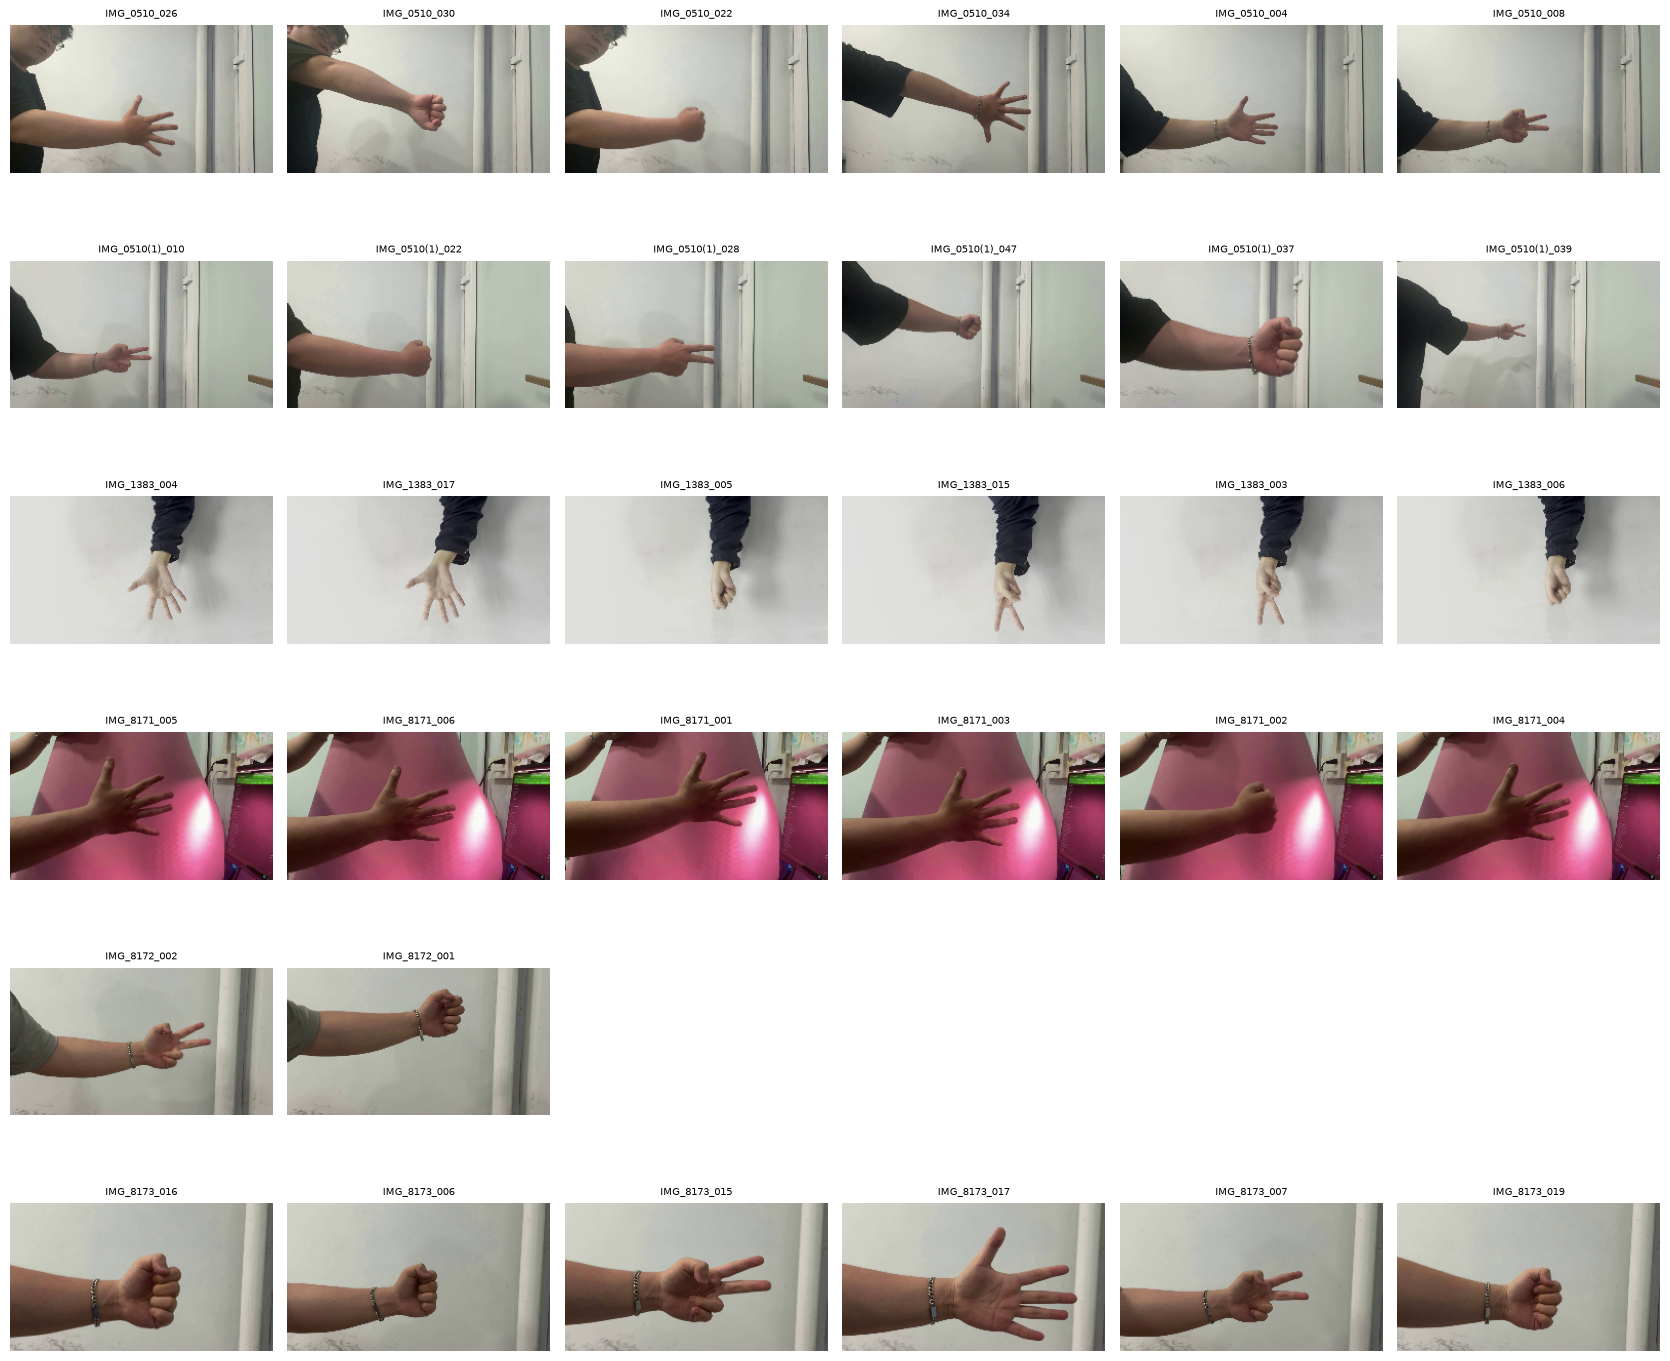

Đã lưu: C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\leak_check\labeled_check.csv và C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\leak_check\labeled_mau.png


In [5]:
#cell 5: xuất bảng CSV và ảnh ghép khung mẫu từng nhóm để nhìn bằng mắt
import matplotlib.pyplot as plt
df.drop(columns=["path"]).to_csv(OUT / "labeled_check.csv", index=False, encoding="utf-8-sig")
K = 6; rng = np.random.default_rng(0)
fig, ax = plt.subplots(len(names), K, figsize=(2.8 * K, 2.4 * len(names)))
for r, a in enumerate(names):
    idx = rng.choice(np.where(g == a)[0], min(K, (g == a).sum()), replace=False)
    for c in range(K):
        ax[r, c].axis("off")
        if c < len(idx) and len(F[idx[c]]) > 1:
            f = F[idx[c]][1]; w = int(f.shape[1] * 144 / f.shape[0])
            ax[r, c].imshow(cv2.cvtColor(cv2.resize(f, (w, 144)), cv2.COLOR_BGR2RGB)); ax[r, c].set_title(df.fn[idx[c]], fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "labeled_mau.png", dpi=110); plt.show()
print("Đã lưu:", OUT / "labeled_check.csv", "và", OUT / "labeled_mau.png")